In [3]:
from anemone.forwards import ForwardLaplace3
from anemone import constants as c
from anemone.transforms import Hankel, invLaplace
from anemone.physics import rte_matrix as rte, freespace_u0 as u0, drte_dsigma
from anemone.physics import refl_transverse_electric as rte0
import torch
from numpy import ndarray

In [4]:
from anemone.physics import *
def calc_rte_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0, collapse_matrices=True):
    thick = torch.vstack([torch.zeros_like(thickness[:1]), thickness])

    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, 1, dims=0)
    un1[0] = u0
    un2 = un*1.

    euh_p = torch.exp(un1*thick)

    euh_m = 1./euh_p
    unratio = un2/un1
    d_un  = 1.-unratio
    m_un  = 1.+unratio

    propmat = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
    propmat[0, 0] = m_un*euh_p
    propmat[0, 1] = d_un*euh_p
    propmat[1, 0] = d_un*euh_m
    propmat[1, 1] = m_un*euh_m
    if collapse_matrices:
        answer = torch.tensor([1., 0.], dtype=torch.complex128, device=thickness.device)
        answer = torch.einsum('ij...,j...->i...', propmat[:,:,-1], answer)
        for i in range(propmat.shape[2]-2, -1, -1):
            answer = torch.einsum('ij...,j...->i...', propmat[:,:,i], answer)
        rte = answer[1] / answer[0]
    else:
        propmat_dsigma1 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
        propmat_dsigma1[0, 0] = euh_p*(thick + thick*unratio - unratio/un1)
        propmat_dsigma1[0, 1] = euh_p*(thick - thick*unratio + unratio/un1)
        propmat_dsigma1[1, 0] = euh_m*(-thick + thick*unratio + unratio/un1)
        propmat_dsigma1[1, 1] = euh_m*(-thick - thick*unratio - unratio/un1)

        propmat_dsigma2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
        propmat_dsigma2[0, 0] = ( unratio/un2)*euh_p
        propmat_dsigma2[0, 1] = (-unratio/un2)*euh_p
        propmat_dsigma2[1, 0] = (-unratio/un2)*euh_m
        propmat_dsigma2[1, 1] = ( unratio/un2)*euh_m    
        backpropmat = propmat.clone()

        propmat_dsigma = torch.einsum('ij...,jk...->ik...', propmat[:,:,:-1], propmat_dsigma1)\
                        +torch.einsum('ij...,jk...->ik...', propmat_dsigma2, propmat[:,:,:-1])


        for i in range(1,propmat.shape[2]):
            propmat[:,:,i] = torch.einsum('ij...,jk...->ik...', propmat[:,:, i-1], propmat[:,:, i])

        for i in range(propmat.shape[2]-2, -1, -1):
            backpropmat[:,:,i] = torch.einsum('ij...,jk...->ik...', backpropmat[:,:, i], backpropmat[:,:, i+1])


        # tmp = torch.einsum('ij...,jk...->ik...', propmat_dsigma[:,:,0], backpropmat[:,:,2])
        d_rte = torch.einsum('ij...,jk...->ik...', propmat[:,:,:-1], propmat_dsigma)
        d_rte = torch.einsum('ij...,jk...->ik...', d_rte, backpropmat[:,:, 1:])
        rte = d_rte[1,0] / d_rte[0,0]
        rte = 1j*mu[1:-1]*omega*rte / (2.*un2[1:-1])
    return rte

def rte_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    rte = calc_rte_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon)
    return torch.nan_to_num(rte)

def drte_dsigma(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    dsigma = calc_rte_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, collapse_matrices=False)
    return torch.nan_to_num(dsigma)

In [5]:
from anemone.physics import *
def calc_rte_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0, collapse_matrices=True):
    thick = torch.vstack([torch.zeros_like(thickness[:1]), thickness])

    lambda2 = wave_length**2
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    un = torch.sqrt(lambda2 - k2)
    u0 = freespace_u0(omega, wave_length)
    un1 = torch.roll(un, 1, dims=0)
    un1[0] = u0
    un2 = un*1.

    euh_p = torch.exp(un1*thick)

    euh_m = 1./euh_p
    unratio = un2/un1
    d_un  = 1.-unratio
    m_un  = 1.+unratio

    propmat = torch.zeros((2,2, m_un.shape[0]+2)+m_un.shape[1:], dtype=torch.complex128)
    propmat[0,0,:2] = 1.
    propmat[1,1,:2] = 1.

    propmat[0, 0, 2:] = m_un*euh_p
    propmat[0, 1, 2:] = d_un*euh_p
    propmat[1, 0, 2:] = d_un*euh_m
    propmat[1, 1, 2:] = m_un*euh_m
    if collapse_matrices:
        answer = torch.tensor([1., 0.], dtype=torch.complex128, device=thickness.device)
        answer = torch.einsum('ij...,j...->i...', propmat[:,:,-1], answer)
        for i in range(propmat.shape[2]-2, -1, -1):
            answer = torch.einsum('ij...,j...->i...', propmat[:,:,i], answer)
        rte = answer[1] / answer[0]
    else:
        backpropmat = propmat.clone()
        propmat_dsigma1 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
        propmat_dsigma1[0, 0] = euh_p*(thick + thick*unratio - unratio/un1)
        propmat_dsigma1[0, 1] = euh_p*(thick - thick*unratio + unratio/un1)
        propmat_dsigma1[1, 0] = euh_m*(-thick + thick*unratio + unratio/un1)
        propmat_dsigma1[1, 1] = euh_m*(-thick - thick*unratio - unratio/un1)

        propmat_dsigma2 = torch.empty((2,2)+m_un.shape, dtype=torch.complex128)
        propmat_dsigma2[0, 0] = ( unratio/un2)*euh_p
        propmat_dsigma2[0, 1] = (-unratio/un2)*euh_p
        propmat_dsigma2[1, 0] = (-unratio/un2)*euh_m
        propmat_dsigma2[1, 1] = ( unratio/un2)*euh_m    
        
        propmat_dsigma = torch.einsum('ij...,jk...->ik...', propmat_dsigma1, propmat[:,:,1:-1])\
                        +torch.einsum('ij...,jk...->ik...', propmat[:,:,2:], propmat_dsigma2)


        for i in range(1,propmat.shape[2]):
            propmat[:,:,i] = torch.einsum('ij...,jk...->ik...', propmat[:,:, i-1], propmat[:,:, i])

        for i in range(propmat.shape[2]-2, -1, -1):
            backpropmat[:,:,i] = torch.einsum('ij...,jk...->ik...', backpropmat[:,:, i], backpropmat[:,:, i+1])


        # tmp = torch.einsum('ij...,jk...->ik...', propmat_dsigma[:,:,0], backpropmat[:,:,2])
        d_rte = torch.einsum('ij...,jk...->ik...', propmat[:,:,1:-1], propmat_dsigma)
        d_rte = torch.einsum('ij...,jk...->ik...', d_rte, backpropmat[:,:, 2:])
        rte = d_rte[1,0] / d_rte[0,0]
        rte = 1j*mu*omega*rte / (2.*un2)
    return rte

def rte_matrix(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    rte = calc_rte_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon)
    return torch.nan_to_num(rte)

def drte_dsigma(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    dsigma = calc_rte_matrix(sigma, thickness, omega, wave_length, mu=mu, epsilon=epsilon, collapse_matrices=False)
    return torch.nan_to_num(dsigma)

In [6]:
class ForwardMatrix(ForwardLaplace3):
    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
                if self.tmp_u0 is None: self.tmp_u0 = u0(self.omega, self.lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz) / self.tmp_u0 

                intg = rte_matrix(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb**2 / c.fourpi
            return res.swapaxes(-2,-1)

        hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.geomz is None:
            self.geomz = self.source.geomz(self.receiver, r).to(torch.double)
            self.r=r
        else:
            assert torch.all(self.r==r)
        Ht = torch.einsum('...ik,...jk',  self.geomz, HR)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t).mT.squeeze()
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()  
        
    def jacobian(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
                if self.tmp_u0 is None: self.tmp_u0 = u0(self.omega, self.lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz) / self.tmp_u0 

                intg = drte_dsigma(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb**2 / c.fourpi
            return res.swapaxes(-2,-1)

        hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        if self.geomz is None:
            self.geomz = self.source.geomz(self.receiver, r).to(torch.double)
            self.r=r
        else:
            assert torch.all(self.r==r)
        Ht = torch.einsum('...ik,...jk',  self.geomz, HR)

        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t).mT.squeeze()
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()  

    def __call__(self, rho, thickness, jac=False):
        self.rho = ((rho+0j)[..., None, None])#.to(self.device)
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = ((thickness+0j)[..., None, None])#.to(self.device)
        if jac:
            import numpy as np
            G = self.jacobian().numpy()*c.mu0
            while len(G)!= len(rho):
                G = np.pad(G, [(1,0),(0,0)], constant_values=0.0)
            return torch.from_numpy(G).to(self.device)
        else:            
            return self.forward()*c.mu0

In [7]:
from anemone.experiment import Loop, Receiver, Waveform

t = torch.logspace(-5, -3, 40)
tx = Loop.square(40)
rx = Receiver()
waveform = Waveform.example()


In [8]:
fwr0 = ForwardLaplace3(tx, rx, t, waveform)
fwr1 = ForwardMatrix(tx, rx, t, waveform)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


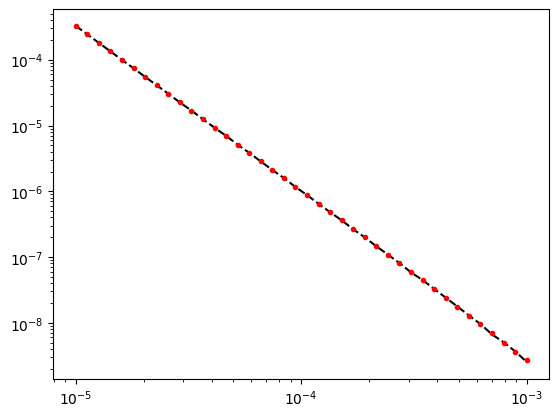

In [9]:
import matplotlib.pyplot as plt
import numpy as np

rho = torch.ones(16, dtype=torch.double)*40.
thick = torch.logspace(-1, 1.2, 15, dtype=torch.double)
dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)

plt.figure()
plt.loglog(fwr0.times, dbdt0, 'k--')
plt.loglog(fwr1.times, dbdt1, 'r.')

In [11]:
dm = rho*0.02
rho_mat = rho[:, None] + torch.eye(len(rho))*dm
#Gt = 
if 'dbdt_mat' not in locals():
    dbdt_mat = fwr0(rho_mat, thick)
G0 = (dbdt_mat - dbdt0[None, :]) / dm[:, None]
G0 = G0.numpy()

In [14]:
G1 = fwr1(rho, thick, jac=True)
G1 /= rho[:, None]**2

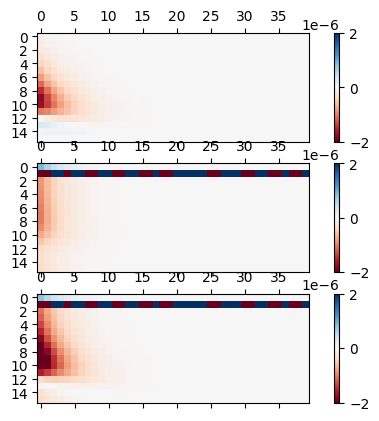

In [15]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(3,1)
pcm = axs[0].matshow(G0, cmap='RdBu', vmin=-2e-6, vmax=2e-6)
plt.colorbar(pcm)

pcm = axs[1].matshow(G1, cmap='RdBu', vmin=-2e-6, vmax=2e-6)
plt.colorbar(pcm)

pcm = axs[2].matshow(G1+G0, cmap='RdBu', vmin=-2e-6, vmax=2e-6)
plt.colorbar(pcm)
